# K-Means Clustering — Learn with Dr. Jyoti


**Goal:** Discover groups in unlabeled data using K-Means.

We will use the **Iris dataset**, scale the features, use the **Elbow Method** to choose K, and then visualize the final clusters.

## 1. Import the libraries

We only need a few libraries for this demonstration.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

## 2. Load the real dataset

The Iris dataset contains measurements of iris flowers. For K-Means, we will **not use the species labels to create the clusters**. The algorithm will discover groups using only the feature values.

In [ ]:
iris = load_iris()

X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = iris.target

X.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


### What are the features?

- Sepal length
- Sepal width
- Petal length
- Petal width

For K-Means, these are the inputs. The cluster labels will be created by the algorithm.

In [ ]:
X.shape

(150, 4)

## 3. Why do we scale the features?

K-Means uses distance. If one feature has a much larger numerical scale than another, it can dominate the distance calculation.

Standardization changes each feature approximately to mean 0 and standard deviation 1.

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled[:5]

array([[-0.90068117,  1.01900435, -1.34022653, -1.3154443 ],
       [-1.14301691, -0.13197948, -1.34022653, -1.3154443 ],
       [-1.38535265,  0.32841405, -1.39706395, -1.3154443 ],
       [-1.50652052,  0.09821729, -1.2833891 , -1.3154443 ],
       [-1.02184904,  1.24920112, -1.34022653, -1.3154443 ]])

## 4. Find a suitable K with the Elbow Method

We try several values of K and record **inertia**.

Inertia is the total within-cluster squared distance. As K increases, inertia decreases. We look for the point where the improvement starts becoming much smaller — the **elbow**.

In [ ]:
inertias = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

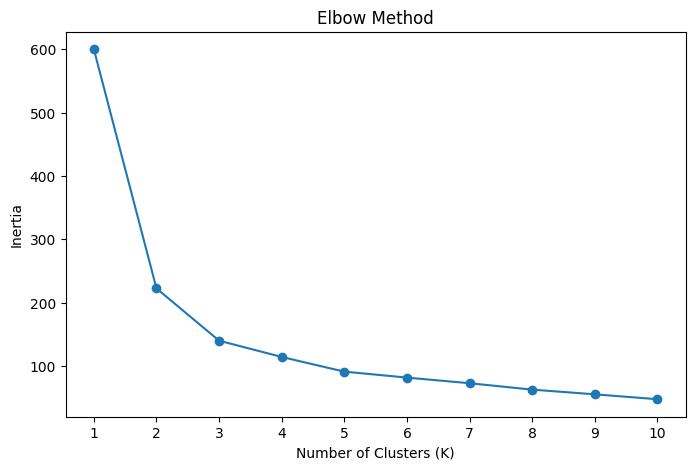

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.xticks(list(k_values))
plt.show()

### Interpretation

For this dataset, **K = 3** is a natural choice to demonstrate K-Means. Remember: the elbow method is a heuristic, not a mathematical guarantee of the one correct K.

## 5. Train K-Means with K = 3

Now the algorithm follows the loop from the video:

1. Choose K
2. Place initial centroids
3. Assign each point to its nearest centroid
4. Move each centroid to the mean of its assigned points
5. Repeat until the solution stabilizes

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

clusters[:10]

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1], dtype=int32)

## 6. Add the discovered cluster to the data

These labels were created by K-Means. They were **not supplied to the algorithm**.

In [ ]:
result = X.copy()
result['Cluster'] = clusters

result.head(10)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Cluster
0,5.1,3.5,1.4,0.2,1
1,4.9,3.0,1.4,0.2,1
2,4.7,3.2,1.3,0.2,1
3,4.6,3.1,1.5,0.2,1
4,5.0,3.6,1.4,0.2,1
5,5.4,3.9,1.7,0.4,1
6,4.6,3.4,1.4,0.3,1
7,5.0,3.4,1.5,0.2,1
8,4.4,2.9,1.4,0.2,1
9,4.9,3.1,1.5,0.1,1


## 7. Visualize the clusters

To keep the demonstration simple, we visualize two features: **petal length** and **petal width**.

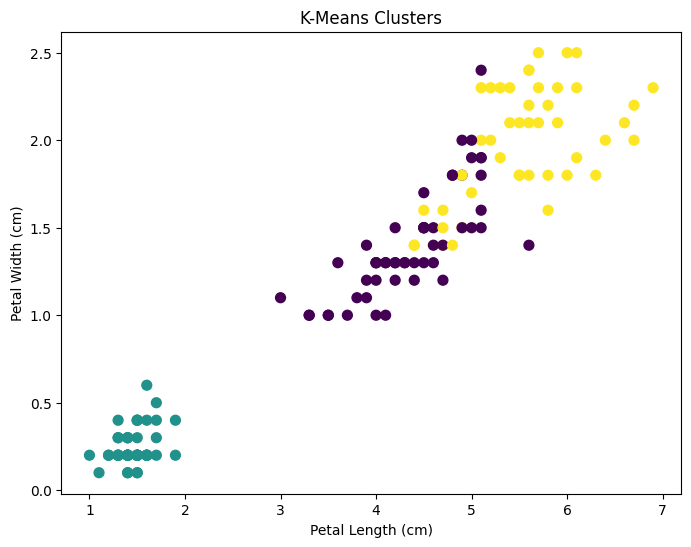

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X['petal length (cm)'],
    X['petal width (cm)'],
    c=clusters,
    s=50
)

plt.xlabel('Petal Length (cm)')
plt.ylabel('Petal Width (cm)')
plt.title('K-Means Clusters')
plt.show()

## 8. Where are the centroids?

The centroid is the mathematical center of a cluster. Because K-Means was trained on scaled data, the centroid coordinates below are also in scaled units.

In [ ]:
centroids = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=X.columns
)

centroids

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.050220,-0.883376,0.347738,0.281527
1,-1.014579,0.853263,-1.304987,-1.254893
2,1.135970,0.088422,0.996155,1.017526


## 9. Final inertia

A smaller inertia means the points are, overall, closer to their assigned centroids. But **inertia alone cannot tell us the best K**, because inertia generally decreases when we add more clusters.

In [ ]:
print('Final inertia:', kmeans.inertia_)

Final inertia: 139.82049635974974


## 10. Optional: compare with the known species labels

This is only for learning. The species labels were **not used to train K-Means**. We can look at them afterward to see how the discovered clusters relate to the known classes.

In a truly unlabeled clustering problem, we would not have these labels.

In [ ]:
comparison = pd.DataFrame({
    'Actual Species': [iris.target_names[i] for i in y],
    'KMeans Cluster': clusters
})

pd.crosstab(comparison['Actual Species'], comparison['KMeans Cluster'])

KMeans Cluster,0,1,2
Actual Species,,,
setosa,0,50,0
versicolor,39,0,11
virginica,14,0,36


## 11. The K-Means workflow

**Data → Scale → Choose K → Initialize centroids → Assign points → Update centroids → Repeat → Final clusters**

### Remember
- **K** = number of clusters
- **Centroid** = cluster center
- **Assign** = send a point to its nearest centroid
- **Update** = calculate the mean of assigned points
- **Repeat** = continue until the solution stabilizes
- **Elbow Method** = a practical way to help choose K
- **Scaling** = important because K-Means uses distance

### One-line mental model
> Choose K centers → assign points to the nearest center → move each center to the mean → repeat until stable.

## Mini Practice

Try changing `n_clusters=3` to `2` and `4`.

Observe how the cluster assignments and inertia change.

Then change the range in the Elbow Method from `1–10` to another range and inspect the curve.